# ĐỀ TÀI 2: PHÂN ĐOẠN ẢNH Y TẾ (MEDICAL IMAGE SEGMENTATION)
## PHẦN (1): U-NET BASELINE (SCRATCH VS PRETRAINED ENCODER)

**Mục tiêu thực hiện:**
1. Cài đặt hoàn chỉnh kiến trúc U-Net từ đầu (From Scratch) theo Ronneberger et al. (2015).
2. Xây dựng U-Net sử dụng Pretrained Encoder (ResNet34 backbone trên ImageNet).
3. Huấn luyện và đánh giá trên tập dữ liệu ảnh y tế (Polyp nội soi Kvasir-SEG / ISIC Skin Lesion).
4. Đánh giá và so sánh định lượng bằng hai độ đo chuẩn: **Dice Score (F1)** và **IoU (Jaccard Index)**, kèm theo số lượng tham số và tốc độ suy luận (FPS).
5. Trực quan hóa mặt nạ phân đoạn dự đoán và biểu đồ học tập.

In [1]:
# 1. Khởi tạo môi trường & Kiểm tra thiết bị phần cứng (GPU / CPU)
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch Version:", torch.__version__)
print("Thiết bị tính toán :", device)
if torch.cuda.is_available():
    print("Tên GPU           :", torch.cuda.get_device_name(0))
    print("VRAM khả dụng     :", f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

PyTorch Version: 2.15.0+cpu
Thiết bị tính toán : cpu


In [2]:
# 2. Chuẩn bị tập dữ liệu (Tạo dữ liệu mẫu hoặc trỏ tới Kvasir-SEG / ISIC)
from download_sample_data import create_synthetic_dataset
from utils.dataset import get_dataloaders, find_image_mask_pairs

DATA_DIR = "data/sample_medical"
if not os.path.exists(os.path.join(DATA_DIR, "images")):
    print("Đang khởi tạo dữ liệu mẫu...")
    create_synthetic_dataset(output_dir=DATA_DIR, num_samples=60, img_size=256)

train_loader, val_loader, test_loader = get_dataloaders(
    data_dir=DATA_DIR,
    img_size=(256, 256),
    batch_size=8,
    train_ratio=0.8,
    val_ratio=0.1
)

Đang khởi tạo dữ liệu mẫu...
[*] Đang tạo 60 ảnh y tế mẫu tại: data/sample_medical
[✓] Đã tạo thành công 60 mẫu tại:
    - Ảnh gốc : data/sample_medical\images
    - Mặt nạ   : data/sample_medical\masks
Dataset split: Train = 96, Val = 12, Test = 12 (Tổng: 120)


c:\Users\LENOVO\Downloads\Medical_Unet-unet-baseline\Medical_Unet-unet-baseline\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


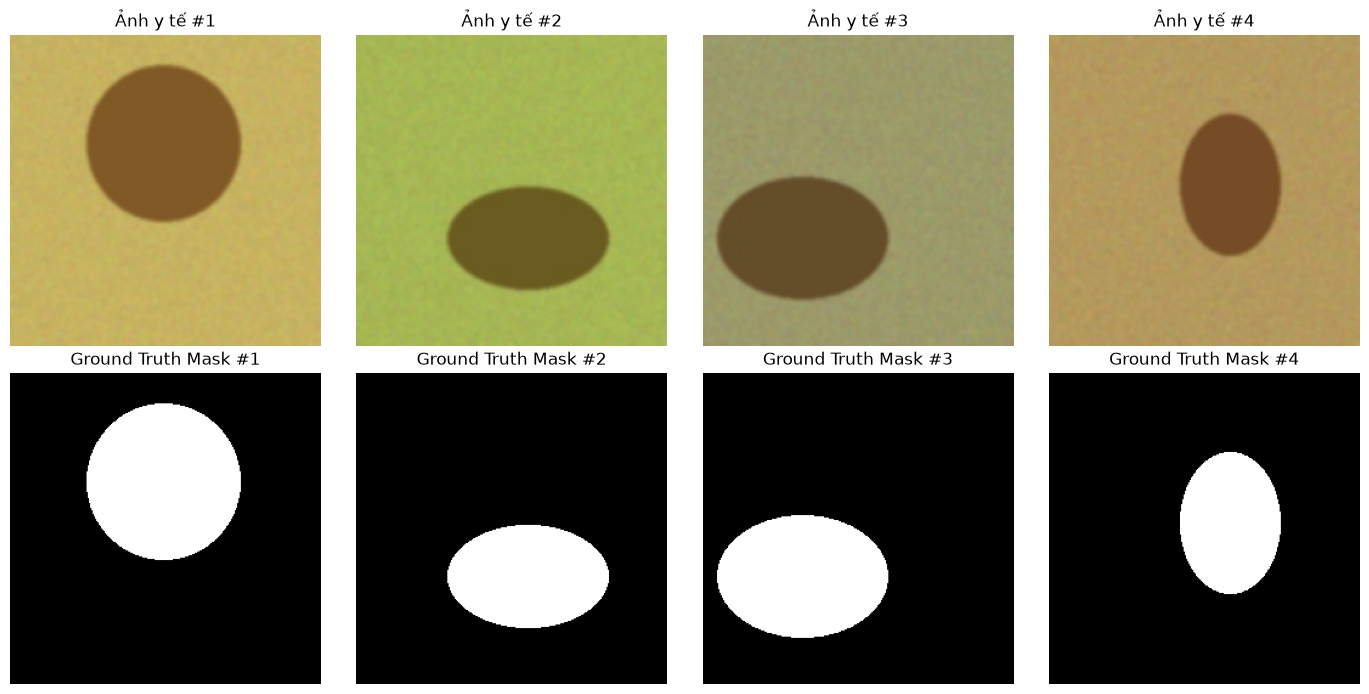

In [3]:
# 3. Khám phá & Trực quan hóa dữ liệu huấn luyện
images, masks = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i in range(4):
    img_vis = images[i].permute(1, 2, 0).cpu().numpy()
    img_vis = np.clip(img_vis * std + mean, 0, 1)
    mask_vis = masks[i].squeeze().cpu().numpy()
    
    axes[0, i].imshow(img_vis)
    axes[0, i].set_title(f"Ảnh y tế #{i+1}")
    axes[0, i].axis("off")
    
    axes[1, i].imshow(mask_vis, cmap="gray")
    axes[1, i].set_title(f"Ground Truth Mask #{i+1}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [4]:
# 4. Khởi tạo 2 Mô hình: U-Net Scratch vs U-Net Pretrained
from models.unet_scratch import UNetScratch
from models.unet_pretrained import build_unet

model_scratch = UNetScratch(in_channels=3, num_classes=1).to(device)
model_pretrained = build_unet(model_type="pretrained", backbone="resnet34", pretrained=True, in_channels=3, num_classes=1).to(device)

print(f"[U-Net Scratch]    Số lượng tham số: {model_scratch.count_parameters():,}")
print(f"[U-Net Pretrained] Số lượng tham số: {model_pretrained.count_parameters():,}")

c:\Users\LENOVO\Downloads\Medical_Unet-unet-baseline\Medical_Unet-unet-baseline\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[U-Net Scratch]    Số lượng tham số: 31,037,633
[U-Net Pretrained] Số lượng tham số: 24,436,369


In [5]:
# 5. Huấn luyện Mô hình 1: U-Net Scratch
!python train.py --model scratch --data_dir data/sample_medical --epochs 15 --batch_size 8 --lr 1e-4

Dataset split: Train = 96, Val = 12, Test = 12 (Tổng: 120)



  [Train]:   0%|          | 0/12 [00:00<?, ?it/s]c:\Users\LENOVO\Downloads\Medical_Unet-unet-baseline\Medical_Unet-unet-baseline\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

  [Train]: 100%|██████████| 12/12 [02:22<00:00, 11.72s/it, Loss=0.9154, Dice=0.9493]
                                                                                    

  [Val]: 100%|██████████| 2/2 [00:06<00:00,  3.12s/it, Loss=1.5199, Dice=0.1813]
                                                                                

  [Train]: 100%|██████████| 12/12 [04:02<00:00, 20.83s/it, Loss=0.8906, Dice=0.9608]
                                                                                    

  [Val]: 100%|██████████| 2/2 [00:09<00:00,  4.54s/it, Loss=1.2251, Dice=0.9659]
                                                                            

In [6]:
# 6. Huấn luyện Mô hình 2: U-Net Pretrained (ResNet34)
!python train.py --model pretrained --backbone resnet34 --data_dir data/sample_medical --epochs 15 --batch_size 8 --lr 1e-4

Dataset split: Train = 96, Val = 12, Test = 12 (Tổng: 120)



  [Train]:   0%|          | 0/12 [00:00<?, ?it/s]c:\Users\LENOVO\Downloads\Medical_Unet-unet-baseline\Medical_Unet-unet-baseline\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

  [Train]: 100%|██████████| 12/12 [00:26<00:00,  2.27s/it, Loss=1.1112, Dice=0.6066]
                                                                                    

  [Val]: 100%|██████████| 2/2 [00:01<00:00,  1.92it/s, Loss=1.4401, Dice=0.3853]
                                                                                

  [Train]: 100%|██████████| 12/12 [00:28<00:00,  2.26s/it, Loss=1.0016, Dice=0.7586]
                                                                                    

  [Val]: 100%|██████████| 2/2 [00:01<00:00,  1.88it/s, Loss=1.2957, Dice=0.5302]
                                                                            

In [7]:
# 7. Đánh giá & Xuất bảng so sánh định lượng trên tập Test
!python evaluate.py --data_dir data/sample_medical --scratch_ckpt checkpoints/best_unet_scratch.pth --pretrained_ckpt checkpoints/best_unet_pretrained_resnet34.pth

Dataset split: Train = 96, Val = 12, Test = 12 (Tổng: 120)



Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]c:\Users\LENOVO\Downloads\Medical_Unet-unet-baseline\Medical_Unet-unet-baseline\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

Evaluating: 100%|██████████| 2/2 [00:09<00:00,  4.64s/it]
                                                         

Evaluating: 100%|██████████| 2/2 [00:01<00:00,  1.10it/s]
                                                         


--- Biểu đồ Đường cong Huấn luyện ---


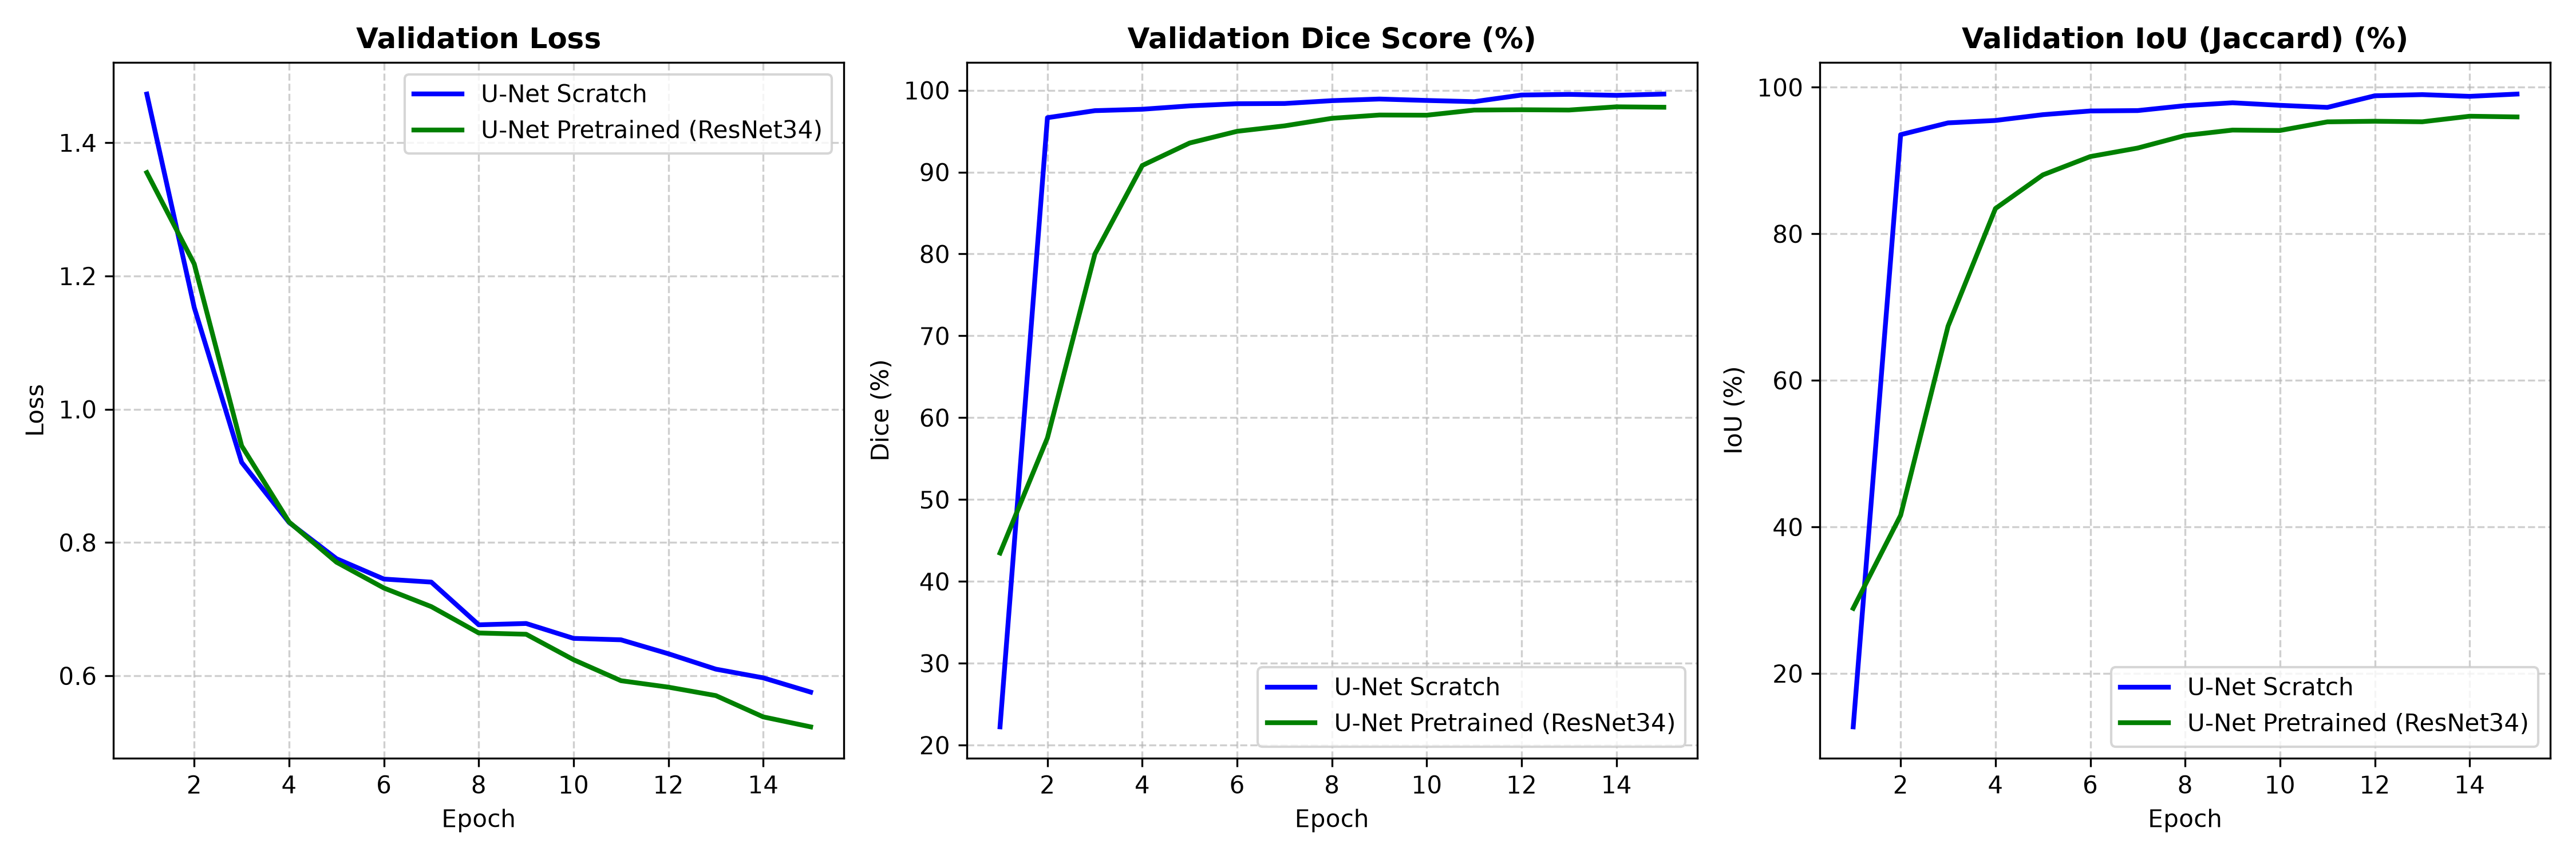

--- So sánh Trực quan Mặt nạ Dự đoán ---


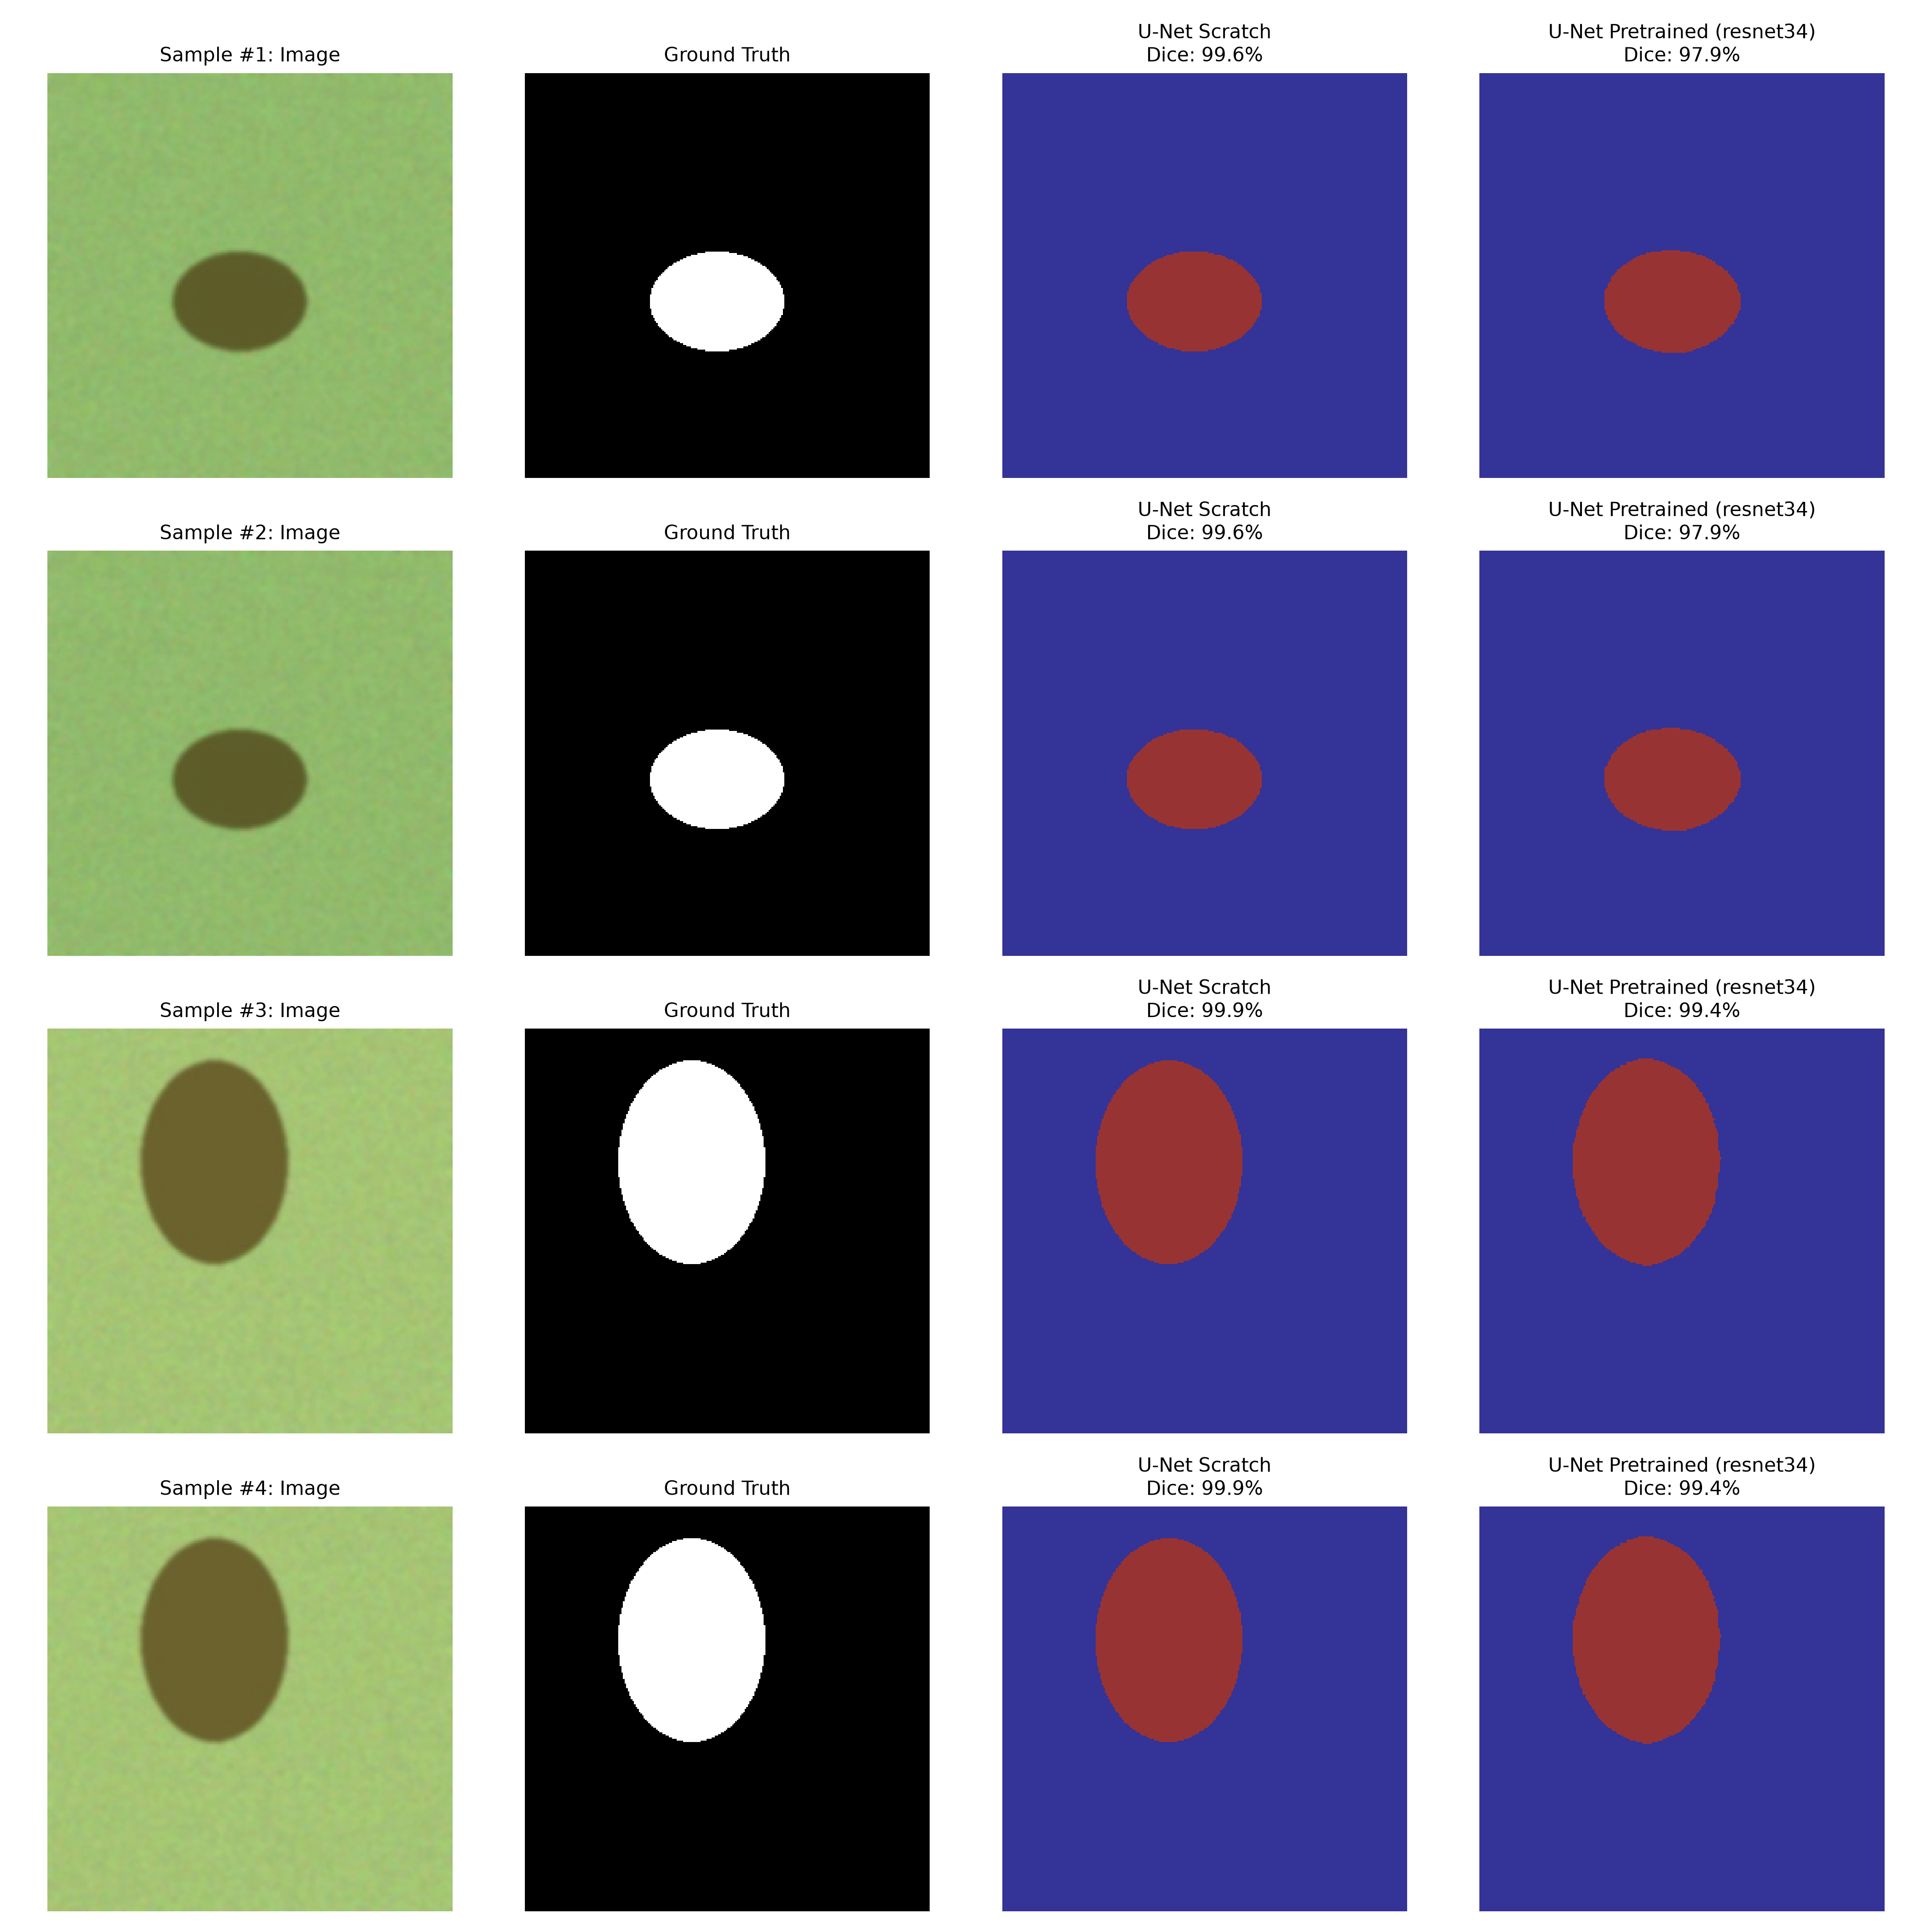

In [8]:
# 8. Trực quan hóa Biểu đồ Huấn luyện & Dự đoán phân đoạn
!python visualize.py --data_dir data/sample_medical --scratch_ckpt checkpoints/best_unet_scratch.pth --pretrained_ckpt checkpoints/best_unet_pretrained_resnet34.pth

# Hiển thị ảnh kết quả trực tiếp trong notebook
from IPython.display import Image, display
if os.path.exists("results/learning_curves.png"):
    print("--- Biểu đồ Đường cong Huấn luyện ---")
    display(Image("results/learning_curves.png"))
if os.path.exists("results/segmentation_comparison.png"):
    print("--- So sánh Trực quan Mặt nạ Dự đoán ---")
    display(Image("results/segmentation_comparison.png"))